In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, PolynomialFeatures,
                                   FunctionTransformer, TargetEncoder, OrdinalEncoder)
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             median_absolute_error, r2_score)
from sklearn.ensemble import HistGradientBoostingRegressor


SEED = 7

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv('/content/drive/MyDrive/Курс/ДЗ1/used_cars.csv')
print(df.shape)
df.head()

(4009, 12)


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


# EDA

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


Одни категариальные данные. Но milage и price должны быть численными

In [5]:
df['milage'] = df['milage'].str.replace(r'\D', '', regex=True).astype(int)
df['price'] = df['price'].str.replace(r'\D', '', regex=True).astype(int)
df['age'] = 2024 - df['model_year']
df = df.replace('–', np.nan)
df['transmission'] = df['transmission'].replace(['2','F', 'SCHEDULED FOR OR IN PRODUCTION'], np.nan)

In [6]:
cat = ['brand', 'model', 'model_year', 'fuel_type', 'engine',
          'transmission', 'ext_col', 'int_col', 'accident', 'clean_title']
stat = pd.DataFrame()
stat['Кол-во Nan'] = df[cat].isna().sum(axis=0)
stat['Кол-во уникальных'] = df[cat].nunique()
stat

,Кол-во Nan,Кол-во уникальных
brand,0,57
model,0,1898
model_year,0,34
fuel_type,215,6
engine,45,1145
transmission,10,58
ext_col,15,318
int_col,133,155
accident,113,2
clean_title,596,1


In [7]:
df['engine'] = df['engine'].replace('–', np.nan)
df['fuel_type'] = df['fuel_type'].replace('not supported', np.nan)
df['hp'] = df['engine'].str.extract(r'(\d+\.?\d*)HP').astype(float)
df['liter'] = df['engine'].str.extract(r'(\d+\.?\d*)\s?L').astype(float)
# тип
bool_type = [
    df['engine'].str.lower().str.contains(r'electric', na=False) & df['liter'].isna(),  #элетроная
    df['engine'].str.lower().str.contains(r'electric', na=False) & ~df['liter'].isna() |
    df['engine'].str.lower().str.contains(r'hybrid', na=False),                         #гибрид
    ~df['engine'].str.lower().str.contains(r'electric', na=False) & ~df['liter'].isna() #бинзиновая
]
df['engine_type'] = np.select(bool_type, ['electric','hybrid', 'oil'], default=None)

c1 = df['engine'].str.extract(r'(\d+)\s*Cylinder')[0]
c2 = df['engine'].str.extract(r'(?:V|I)-?(\d+)')[0]
df['cylinder'] = c1.fillna(c2).astype(float)

In [8]:
df['is_base'] = df['model'].str.contains('Base', na=False)
df['is_sport'] = df['model'].str.contains(r'\b(?:AMG|GT|SS|NISMO|Quadrifoglio|R-Dynamic)\b', na=False)
df['is_premium'] = df['model'].str.contains(r'\b(?:Premium|Limited|Platinum|Luxury|Plus)\b', na=False)

In [9]:
df['clean_title'] = ~df['clean_title'].isna()
df['accident'] = df['accident']=='At least 1 accident or damage reported'

In [10]:
df.describe().round(2)

,model_year,milage,price,age,hp,liter,cylinder
count,4009.00,4009.00,4009.00,4009.00,3201.00,3792.00,3601.00
mean,2015.52,64717.55,44553.19,8.48,332.21,3.68,6.23
std,6.10,52296.60,78710.64,6.10,122.26,1.42,1.71
min,1974.00,100.00,2000.00,0.00,70.00,0.65,3.00
25%,2012.00,23044.00,17200.00,4.00,248.00,2.50,4.00
50%,2017.00,52775.00,31000.00,7.00,310.00,3.50,6.00
75%,2020.00,94100.00,49990.00,12.00,400.00,4.70,8.00
max,2024.00,405000.00,2954083.00,50.00,1020.00,8.40,12.00


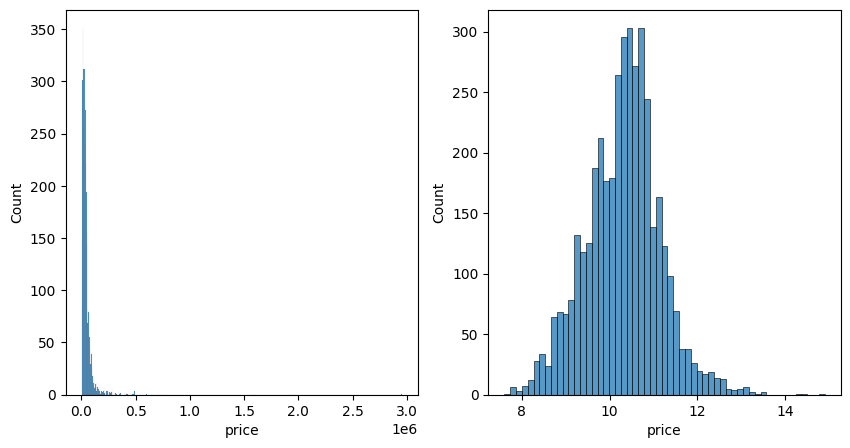

In [11]:
fig, axs = plt.subplots(1,2, figsize=(10,5))

sns.histplot(df['price'], ax=axs[0])
sns.histplot(np.log(df['price']), ax=axs[1]);

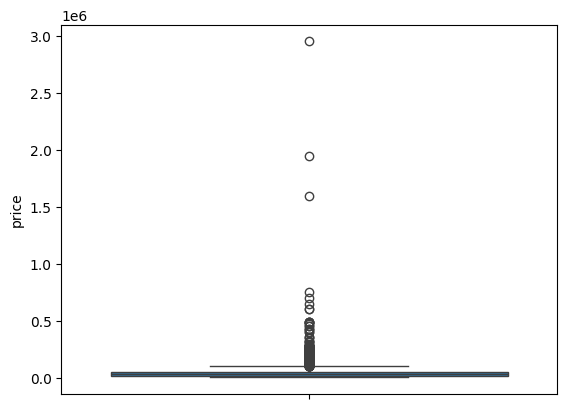

In [12]:
sns.boxplot(df['price']);

In [13]:
df['log_price'] = np.log(df['price'])

In [14]:
color = ['black', 'white', 'grey', 'silver', 'blue', 'red',
         'green', 'brown', 'gold', 'beige','orange', 'yellow','purple']
synonim = {
    'gray': 'grey',
    'blu' : 'blue',
    'ebony': 'black',
    'blk': 'black',
    }
pattern = r'('+'|'.join(color+list(synonim.keys())) + r')'
df['ext_color_base'] = df['ext_col'].str.lower().str.extract(pattern, expand=False)
df['ext_color_base'] = df['ext_color_base'].replace(synonim)
df['ext_color_base'] = df['ext_color_base'].fillna('other')

df['int_color_base'] = df['int_col'].str.lower().str.extract(pattern, expand=False)
df['int_color_base'] = df['int_color_base'].replace(synonim)
df['int_color_base'] = df['int_color_base'].fillna('other')

In [15]:
df['speed'] = df['transmission'].str.lower().str.extract(r'(\d+)-?\s?sp(?:ee)?d').astype(float)
df['is_automatic'] = df['transmission'].str.contains('Automatic|Transmission|A/T|Variable|CVT|Auto', case=False, na=False)

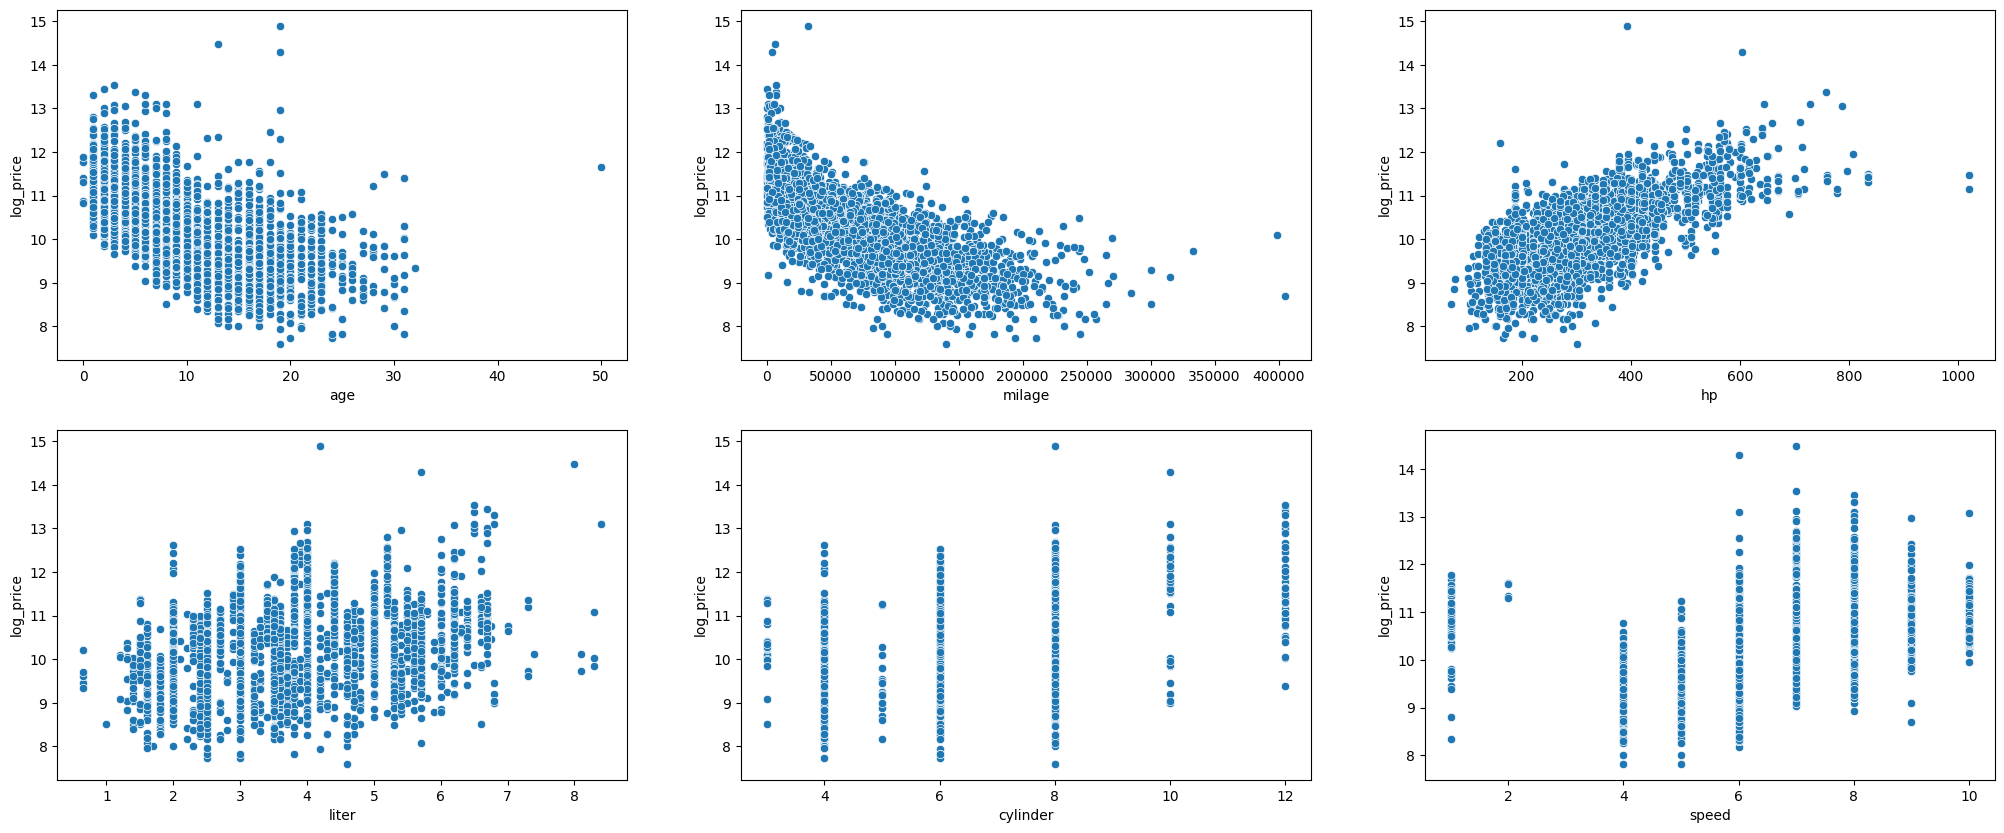

In [16]:
fig, axs = plt.subplots(2,3, figsize=(25,10))
axs = axs.flatten()
num = ['age', 'milage', 'hp', 'liter', 'cylinder', 'speed']
for i, col in enumerate(num):
  sns.scatterplot(df, x=col, y='log_price', ax=axs[i])

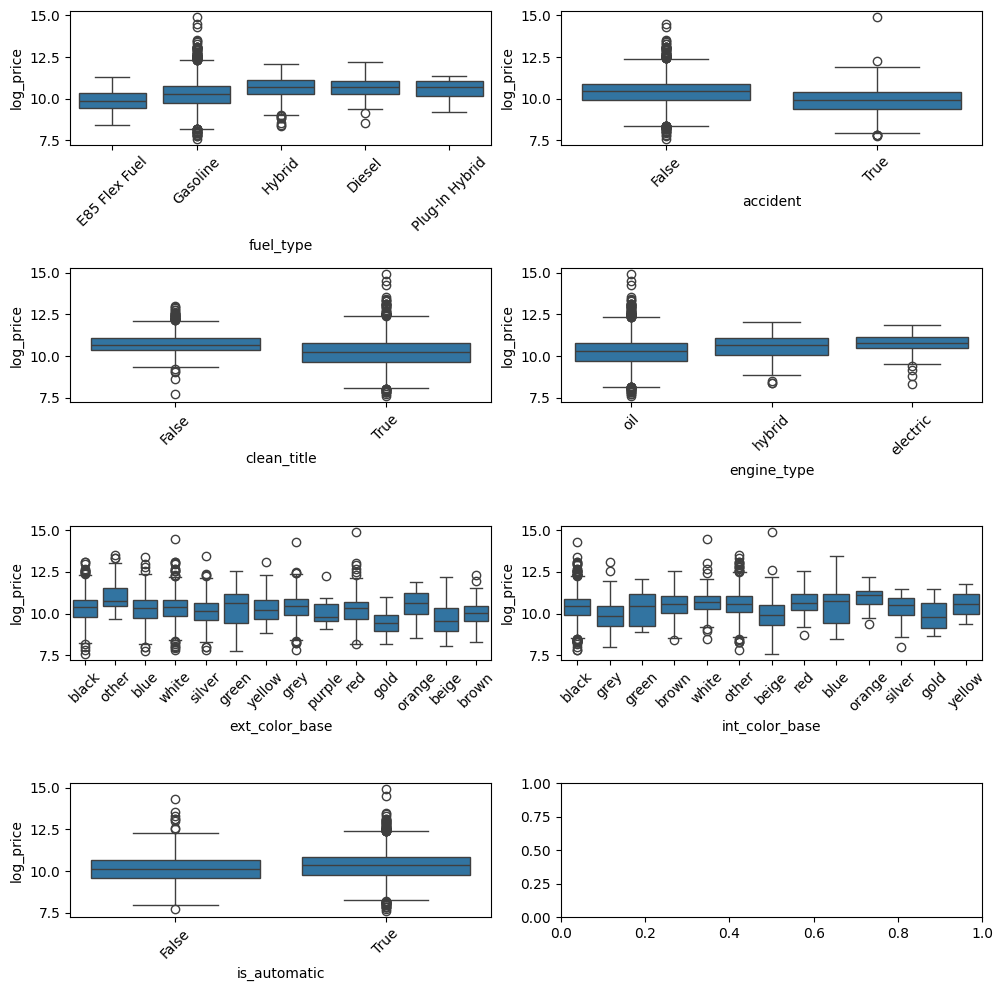

In [17]:
fig, axs = plt.subplots(4,2, figsize=(10,10))
axs = axs.flatten()
cat = ['fuel_type', 'accident', 'clean_title', 'engine_type',
       'ext_color_base', 'int_color_base', 'is_automatic']
for i, col in enumerate(cat):
  sns.boxplot(df, x=col, y='log_price', ax=axs[i])
  axs[i].tick_params(axis='x', rotation=45)
fig.tight_layout()

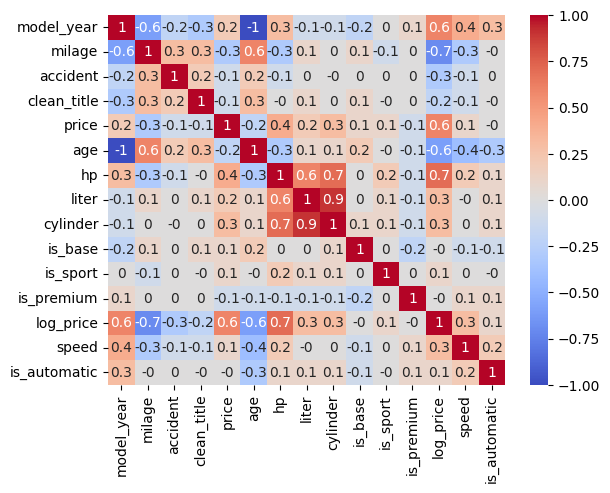

In [18]:
sns.heatmap(df.corr(numeric_only=True).round(1), annot=True,cmap='coolwarm', center=0);

## Анализ пропусков

In [19]:
df.isna().sum()

,0
brand,0
model,0
model_year,0
milage,0
fuel_type,217
engine,45
transmission,10
ext_col,15
int_col,133
accident,0


In [20]:
df.loc[df['fuel_type'].isna(), 'engine_type'].value_counts()

,count
engine_type,
electric,160
hybrid,7


In [21]:
df['fuel_type'].unique()

array(['E85 Flex Fuel', 'Gasoline', 'Hybrid', nan, 'Diesel',
       'Plug-In Hybrid'], dtype=object)

# Гипотезы
**H1:** Использование log цены, даст лучшый показатель по RMSE

**H2:** Линейная модель будет работать не хуже не хуже ансамблевых методов, тк по графикам видно, что есть признаки, которые на цену влияют линейно

**H3:** Линейная модель с регуляризацией $L_{2}$ даст лучший результат, чем с регуляризацией $L_{1}$. Так как $L_{2}$ лучше справляется с мультиколиниарностью

**H4:** Признаки со цветом не влияют на цену. Их удаление не снизит RMSE

**H5:** Самыми важными признаками являются hp и мили

**H6:** Если убрать наблюдения с выбросами, где цена больше 1 млн, модели станут работать стабильнее

# Подготовка данных к моделированию

Перед обучением нужно закрыть три вопроса: чем заполнять пропуски, какие признаки отдавать модели, и как считать метрики



### Пропуски

- `fuel_type` (217): по `engine_type` видно, что 160 из них это электромобили, у которых типа топлива просто нет, ещё 7 - гибриды. Пропуск неслучайный, заполнять модой неправильно. Отдельным шагом пайплайна ставлю `Electric` и `Hybrid` там, где это следует из двигателя. У оставшихся 50 колонка `engine` пуста целиком, то есть про машину не известно ничего, их закрывает `SimpleImputer` категорией `Unknown`
- `hp` (808), `cylinder` (408), `liter` (217), `speed` (1836): пропуски там, где не распарсилась строка `engine`/`transmission`. Здесь пропуск восстановим по другим признакам — `hp`, `liter` и `cylinder` сильно скоррелированы (видно на heatmap), поэтому вместо медианы беру `KNNImputer`. Добавляю флаг (`add_indicator=True`) на случай, если сам факт нестандартного описания двигателя является сигналом

In [22]:
def fill_fuel_type(X):
    X = X.copy()
    X['fuel_type'] = X['fuel_type'].replace('not supported', np.nan)
    X.loc[X['fuel_type'].isna() & (X['engine_type'] == 'electric'), 'fuel_type'] = 'Electric'
    X.loc[X['fuel_type'].isna() & (X['engine_type'] == 'hybrid'),   'fuel_type'] = 'Hybrid'
    return X

fuel_filler = FunctionTransformer(fill_fuel_type, feature_names_out='one-to-one')

### Отбор признаков

Исходные текстовые колонки (`engine`, `transmission`, `ext_col`, `int_col`) выбрасываю: из них уже вытащены `hp`, `liter`, `cylinder`, `engine_type`, `speed`, `is_automatic` и базовые цвета.

`model` (1898 уникальных значений на 4009 строк) тоже выбрасываю. Часть информации из него сохранена во флагах `is_base` / `is_sport` / `is_premium`

`model_year` не беру, потому что это ровно `2024 - age` дублирующий признак, а возраст как фактор логичнее

In [23]:
CAT  = ['brand', 'fuel_type', 'ext_color_base', 'int_color_base', 'engine_type']
BOOL = ['accident', 'clean_title', 'is_base', 'is_sport', 'is_premium', 'is_automatic']
NUM  = ['milage', 'age', 'hp', 'liter', 'cylinder', 'speed']

X = df[CAT + BOOL + NUM]
y = df['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED)
print('train:', X_train.shape, ' test:', X_test.shape)
print('цена: train max = ${:,.0f}, test max = ${:,.0f}'.format(y_train.max(), y_test.max()))
print('машин дороже $1 млн:  train =', (y_train > 1e6).sum(), ', test =', (y_test > 1e6).sum())

train: (2806, 17)  test: (1203, 17)
цена: train max = $2,954,083, test max = $1,599,000
машин дороже $1 млн:  train = 2 , test = 1


In [24]:
DEFAULT_TARGET_ENC = ()

def make_prep(cat=CAT, num=NUM, boool=BOOL, poly=False, num_imp=None,
              target_enc=None, ordinal=False):
    if num_imp is None:
        num_imp = KNNImputer(n_neighbors=5, add_indicator=True)
    if target_enc is None:
        target_enc = DEFAULT_TARGET_ENC
    num_steps = [('sc0', StandardScaler()), ('imp', num_imp)]
    if poly:
        num_steps.append(('poly', PolynomialFeatures(2, include_bias=False)))
    num_steps.append(('sc', StandardScaler()))

    cat_enc = (OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1) if ordinal
               else OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=10,
                                  sparse_output=False))
    ohe_cols = [c for c in cat if c not in target_enc]

    transformers = [
        ('num',  Pipeline(num_steps), num),
        ('cat',  Pipeline([('fuel', fuel_filler),
                           ('imp', SimpleImputer(strategy='constant', fill_value='Unknown')),
                           ('enc', cat_enc)]), ohe_cols),
        ('bool', 'passthrough', boool),
    ]
    if target_enc:
        transformers.append(('te', TargetEncoder(target_type='continuous', cv=5,
                                                 random_state=SEED), list(target_enc)))
    return ColumnTransformer(transformers)

def make_model(est, log_target=False, **prep_kw):
    pipe = Pipeline([('prep', make_prep(**prep_kw)), ('model', est)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    return pipe

### Метрики

Задача регрессионная, целевая переменная скошена, поэтому одной метрики мало:

- RMSE
- MAE
- MedAE
- MAPE
- R²

Сравнивать модели буду на кросс-валидации, потому что разброс RMSE между фолдами оказался ~7000$, и по одному числу отличить модели невозможно. Для разницы между двумя моделями считаю парный t-тест по одним и тем же фолдам

In [25]:
RCV = RepeatedKFold(n_splits=5, n_repeats=2, random_state=42)
SCORING = {'rmse': 'neg_root_mean_squared_error',
           'mae':  'neg_mean_absolute_error',
           'r2':   'r2'}

def cv_scores(est, Xt=X_train, yt=y_train, cv=RCV):
    return cross_validate(est, Xt, yt, cv=cv, scoring=SCORING, n_jobs=-1)

def summary(name, r):
    return {'модель': name,
            'RMSE': round(-r['test_rmse'].mean()), 'RMSE_std': round(r['test_rmse'].std()),
            'MAE':  round(-r['test_mae'].mean()),  'MAE_std':  round(r['test_mae'].std()),
            'R2':   round(r['test_r2'].mean(), 3)}

def paired(name_a, a, name_b, b, key='test_rmse'):
    """Средняя разница метрики на одних и тех же фолдах + p-value парного t-теста."""
    da, db = -a[key], -b[key]
    d = da - db
    p = stats.ttest_rel(da, db).pvalue
    print(f'{name_a} - {name_b} [{key[5:].upper()}]: {d.mean():+.0f} (std {d.std():.0f}), '
          f'p = {p:.4f}  ->  {"значимо" if p < 0.05 else "в пределах шума"}')

def report(y_true, pred, name):
    return {'выборка': name,
            'RMSE': round(mean_squared_error(y_true, pred) ** 0.5),
            'MAE': round(mean_absolute_error(y_true, pred)),
            'MedAE': round(median_absolute_error(y_true, pred)),
            'MAPE %': round(np.mean(np.abs((y_true - pred) / y_true)) * 100, 1),
            'R2': round(r2_score(y_true, pred), 3)}

### Подбор инпутера



In [26]:
imputers = {
    'медиана':             SimpleImputer(strategy='median'),
    'медиана + индикатор': SimpleImputer(strategy='median', add_indicator=True),
    'KNN k=5':             KNNImputer(n_neighbors=5, add_indicator=True),
    'KNN k=15':            KNNImputer(n_neighbors=15, add_indicator=True),
}
imp_res = {nm: cv_scores(make_model(LinearRegression(), log_target=True, num_imp=im))
           for nm, im in imputers.items()}
display(pd.DataFrame([summary(nm, r) for nm, r in imp_res.items()]))

paired('медиана + индикатор', imp_res['медиана + индикатор'], 'KNN k=5', imp_res['KNN k=5'], 'test_rmse')
paired('медиана + индикатор', imp_res['медиана + индикатор'], 'KNN k=5', imp_res['KNN k=5'], 'test_mae')
paired('KNN k=5', imp_res['KNN k=5'], 'KNN k=15', imp_res['KNN k=15'], 'test_rmse')

,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,медиана,59486,42748,13983,2652,0.443
1,медиана + индикатор,58742,42898,13923,2593,0.460
2,KNN k=5,56836,43813,13391,2761,0.502
3,KNN k=15,57179,43618,13459,2740,0.495


медиана + индикатор - KNN k=5 [RMSE]: +1906 (std 1446), p = 0.0033  ->  значимо
медиана + индикатор - KNN k=5 [MAE]: +532 (std 446), p = 0.0059  ->  значимо
KNN k=5 - KNN k=15 [RMSE]: -344 (std 591), p = 0.1152  ->  в пределах шума


KNN выигрывает

Почему KNN здесь работает: `hp`, `liter` и `cylinder` скоррелированы на 0.7–0.8 (heatmap в EDA), и если у машины известны объём и число цилиндров, мощность восстанавливается по похожим машинам заметно точнее, чем медианой по всей выборке

Дальше везде `KNNImputer(n_neighbors=5, add_indicator=True)`.

### Подбор кодировщика
Сравниваю четыре варианта на Ridge и на лесе


In [27]:
def enc_variants(est):
    return {
        'OHE':    make_model(est, log_target=True),
        'TargetEnc': make_model(est, log_target=True, target_enc=('brand',)),
        'OrdinalEnc':  make_model(est, log_target=True, ordinal=True),
    }

enc_res = {}
for est_nm, est in [('Ridge', Ridge(alpha=1.0)),
                    ('RF', RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                                 random_state=SEED, n_jobs=-1))]:
    rows = []
    for nm, mdl in enc_variants(est).items():
        r = cv_scores(mdl)
        enc_res[(est_nm, nm)] = r
        rows.append(summary(f'{est_nm}: {nm}', r))
    display(pd.DataFrame(rows))
    for nm in ['TargetEnc', 'OrdinalEnc']:
        paired(f'{est_nm} OHE', enc_res[(est_nm, 'OHE')], f'{est_nm} {nm}', enc_res[(est_nm, nm)])
    print()

,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,Ridge: OHE,56872,43858,13412,2788,0.502
1,Ridge: TargetEnc,55864,44537,13632,2608,0.522
2,Ridge: OrdinalEnc,61100,42692,15959,2925,0.409


Ridge OHE - Ridge TargetEnc [RMSE]: +1008 (std 2193), p = 0.2013  ->  в пределах шума
Ridge OHE - Ridge OrdinalEnc [RMSE]: -4229 (std 2449), p = 0.0006  ->  значимо



,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,RF: OHE,53635,45717,11906,3242,0.564
1,RF: TargetEnc,53326,45943,11582,2960,0.566
2,RF: OrdinalEnc,54012,45618,12378,3221,0.557


RF OHE - RF TargetEnc [RMSE]: +309 (std 1928), p = 0.6422  ->  в пределах шума
RF OHE - RF OrdinalEnc [RMSE]: -377 (std 610), p = 0.0970  ->  в пределах шума



- OrdinalEncoder линейной модели противопоказан. Это логично, тк превращая эти признаки в числа, информацию мы не передаём, а модель ловить её пытается

- Лесу то же кодирование мешает заметно меньше.Деревья режут по порогам, и порядок категорий для них не смысловой, а лишь неудобный, так чтобы выделить одну марку из произвольной нумерации, нужно два разбиения вместо одного.

- TargetEncoder на brand - в пределах шума. Направление скорее в его пользу, однако утверждать это нельзя: разброс RMSE между фолдами составляет около 44 тысяч, и на таком фоне разница в тысячу неразличима. Причина разброса - выбросы в обучающей выборке

Попробуем убрав выброс

In [28]:
outlier = y_train.idxmax()
display(df.loc[[outlier], ['brand', 'model', 'model_year', 'milage', 'price']])

subsets = {
    'трейн как есть':  (X_train, y_train),
    'без всех > $1M':  (X_train[y_train <= 1e6], y_train[y_train <= 1e6]),
}

clean_res = {}
for sub_nm, (Xs, ys) in subsets.items():
    rows = []
    for est_nm, est in [('Ridge', Ridge(alpha=1.0)),
                        ('RF', RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                                     random_state=SEED, n_jobs=-1))]:
        for enc_nm, mdl in [('OHE', make_model(est, log_target=True)),
                            ('TargetEnc', make_model(est, log_target=True, target_enc=('brand',)))]:
            r = cv_scores(mdl, Xs, ys)
            clean_res[(sub_nm, est_nm, enc_nm)] = r
            rows.append(summary(f'{est_nm}: {enc_nm}', r))
    print(f'=== {sub_nm} ({len(ys)} объектов) ===')
    display(pd.DataFrame(rows))
    for est_nm in ['Ridge', 'RF']:
        paired(f'{est_nm} OHE', clean_res[(sub_nm, est_nm, 'OHE')],
               f'{est_nm} TargetEnc', clean_res[(sub_nm, est_nm, 'TargetEnc')])
    print()

,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000,2954083


=== трейн как есть (2806 объектов) ===


,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,Ridge: OHE,56872,43858,13412,2788,0.502
1,Ridge: TargetEnc,55864,44537,13632,2608,0.522
2,RF: OHE,53635,45717,11906,3242,0.564
3,RF: TargetEnc,53326,45943,11582,2960,0.566


Ridge OHE - Ridge TargetEnc [RMSE]: +1008 (std 2193), p = 0.2013  ->  в пределах шума
RF OHE - RF TargetEnc [RMSE]: +309 (std 1928), p = 0.6422  ->  в пределах шума

=== без всех > $1M (2804 объектов) ===


,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,Ridge: OHE,30101,3772,11796,573,0.660
1,Ridge: TargetEnc,27876,3494,11874,629,0.708
2,RF: OHE,26560,5498,10267,673,0.734
3,RF: TargetEnc,24957,5527,9810,686,0.760


Ridge OHE - Ridge TargetEnc [RMSE]: +2225 (std 2237), p = 0.0153  ->  значимо
RF OHE - RF TargetEnc [RMSE]: +1603 (std 1858), p = 0.0293  ->  значимо



Из-за двух машин дороже миллиона в фолдах, куда они попадали, RMSE считалась почти по одному объекту и разрыв между моделями сжимался почти в ноль. После их удаления эффект проявился в полную величину и вырос вдвое. Таргет-энкодинг по brand обошёл OHE значимо у обеих моделей

Используем далее Таргет-энкодинг по brand

In [29]:
DEFAULT_TARGET_ENC = ('brand',)

# Базовая модель

Возьму 3 Baseline:

1. **Константа** - всегда предсказываем медианную цену
2. **Линейная регрессия на двух признаках** - возраст и пробег. Это «человеческая» логика оценки: старая машина с большим пробегом стоит дешевле.
3. **Линейная регрессия на всех признаках** - сколько даёт вся проделанная работа с парсингом и кодированием.

Все три пока учатся на исходной цене, без логарифма и без регуляризации

In [30]:
simple_prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                      ('sc', StandardScaler())]), ['age', 'milage'])])

baseline = {
    'Константа (медиана)':    make_model(DummyRegressor(strategy='median')),
    'LinReg: age + milage':   Pipeline([('prep', simple_prep), ('model', LinearRegression())]),
    'LinReg: все признаки':   make_model(LinearRegression()),
}
base_sc = {k: cv_scores(v) for k, v in baseline.items()}
display(pd.DataFrame([summary(k, v) for k, v in base_sc.items()]))

,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,Константа (медиана),76153,37620,27578,3051,-0.048
1,LinReg: age + milage,70209,39051,26340,2487,0.150
2,LinReg: все признаки,61387,41673,22585,2047,0.395


1. Возраст и пробег объясняют лишь малую часть цены, то есть очевидная логика «старая машина с большим пробегом дешевле» работает, но описывает цену слабо. Дальше модели сравниваю с третьей строкой
2. В обучающей выборке сидят выбросы, поэтому RMSE, которая сильно наказывает за выбросы, показывает сильный разброс. У MAE такой проблемы нет, поэтому решения дальше принимаю по ней, а RMSE привожу, потому что через неё сформулированы гипотезы

# Проверка гипотез

## H1. Обучение на log(price) даст лучший RMSE

Сравниваю одну и ту же модель на `price` и на `log(price)`. Метрики в обоих случаях считаю **в долларах**: в лог-версии предсказание экспоненцируется внутри `TransformedTargetRegressor`

In [31]:
h1 = {}
for name, est, lg in [('Ridge  ~ price',      Ridge(alpha=1.0), False),
                      ('Ridge  ~ log(price)', Ridge(alpha=1.0), True),
                      ('RF     ~ price',      RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                                                    random_state=SEED, n_jobs=-1), False),
                      ('RF     ~ log(price)', RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                                                    random_state=SEED, n_jobs=-1), True)]:
    h1[name] = cv_scores(make_model(est, log_target=lg))

display(pd.DataFrame([summary(k, v) for k, v in h1.items()]))

for key in ['test_rmse', 'test_mae']:
    paired('Ridge ~ price', h1['Ridge  ~ price'], 'Ridge ~ log', h1['Ridge  ~ log(price)'], key)
    paired('RF    ~ price', h1['RF     ~ price'], 'RF    ~ log',  h1['RF     ~ log(price)'], key)

,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,Ridge ~ price,61329,41706,22504,2068,0.396
1,Ridge ~ log(price),55864,44537,13632,2608,0.522
2,RF ~ price,58724,42078,13474,2676,0.411
3,RF ~ log(price),53326,45943,11582,2960,0.566


Ridge ~ price - Ridge ~ log [RMSE]: +5465 (std 3317), p = 0.0008  ->  значимо
RF    ~ price - RF    ~ log [RMSE]: +5399 (std 8224), p = 0.0804  ->  в пределах шума
Ridge ~ price - Ridge ~ log [MAE]: +8872 (std 994), p = 0.0000  ->  значимо
RF    ~ price - RF    ~ log [MAE]: +1891 (std 1700), p = 0.0087  ->  значимо


**H1 подтвердилась для линейной модели, для ансамбля - частично**

Ridge выигрывает от логарифма и по RMSE (61.3k → 55.9k, p = 0.0008), и по MAE (22.5k → 13.6k): цена логнормальна, и в исходной шкале квадратичная ошибка тянет прямую к дорогим машинам, портя предсказания в массовом сегменте. У леса значимо только MAE (13.5k → 11.6k, p = 0.009), а разница по RMSE в пределах шума (p = 0.080)

Дальше все модели учу на `log(price)`

## Подбор гиперпараметров

До сравнения моделей нужно дать каждой её лучшие параметры

In [32]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=SEED)

gs_ridge = GridSearchCV(make_model(Ridge(), log_target=True),
                        {'regressor__model__alpha': np.logspace(-4, 3, 30)},
                        scoring='neg_root_mean_squared_error', cv=cv5,
                        return_train_score=True, n_jobs=-1).fit(X_train, y_train)

gs_lasso = GridSearchCV(make_model(Lasso(max_iter=50000), log_target=True),
                        {'regressor__model__alpha': np.logspace(-6, -1, 20)},
                        scoring='neg_root_mean_squared_error', cv=cv5, n_jobs=-1).fit(X_train, y_train)

gs_rf = GridSearchCV(make_model(RandomForestRegressor(n_estimators=200, random_state=SEED, n_jobs=-1),
                                log_target=True),
                     {'regressor__model__max_features': ['sqrt', 0.5, 1.0],
                      'regressor__model__criterion': ['squared_error', 'absolute_error']},
                     scoring={'rmse': 'neg_root_mean_squared_error',
                              'mae': 'neg_mean_absolute_error'},
                     refit='rmse', cv=cv5, n_jobs=-1).fit(X_train, y_train)

gs_gb = GridSearchCV(make_model(HistGradientBoostingRegressor(random_state=SEED), log_target=True),
                     {'regressor__model__learning_rate': [0.03, 0.1],
                      'regressor__model__max_iter': [50, 100, 200, 400, 500, 600, 800],
                      'regressor__model__max_leaf_nodes': [15, 31]},
                     scoring='neg_root_mean_squared_error', cv=cv5, n_jobs=-1).fit(X_train, y_train)

for nm, gs in [('Ridge', gs_ridge), ('Lasso', gs_lasso), ('RF', gs_rf), ('HistGB', gs_gb)]:
    print(f'{nm}: {gs.best_params_}, CV RMSE = {-gs.best_score_:,.0f}')

alpha_r = gs_ridge.best_params_['regressor__model__alpha']
alpha_l = gs_lasso.best_params_['regressor__model__alpha']

Ridge: {'regressor__model__alpha': np.float64(0.0001)}, CV RMSE = 58,995
Lasso: {'regressor__model__alpha': np.float64(1e-06)}, CV RMSE = 58,996
RF: {'regressor__model__criterion': 'squared_error', 'regressor__model__max_features': 0.5}, CV RMSE = 56,947
HistGB: {'regressor__model__learning_rate': 0.1, 'regressor__model__max_iter': 200, 'regressor__model__max_leaf_nodes': 31}, CV RMSE = 56,442


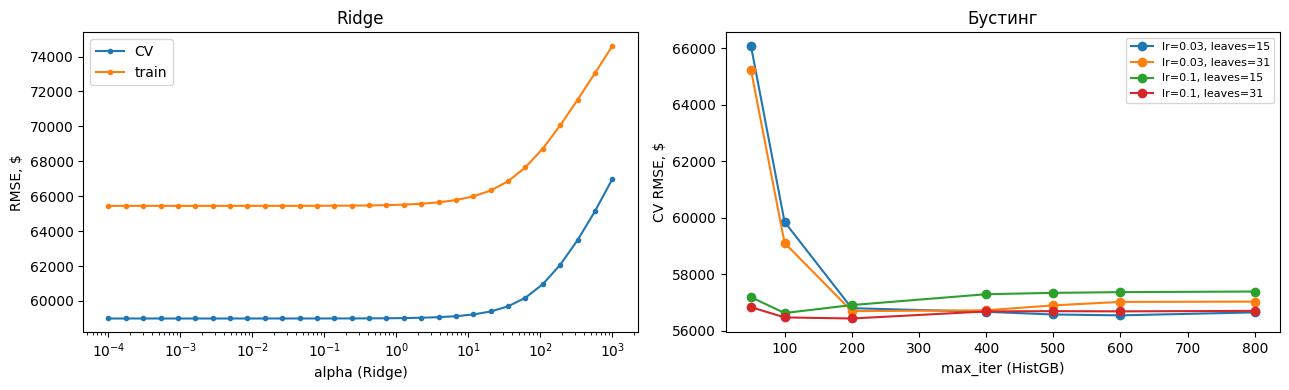

In [33]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

res_r = pd.DataFrame(gs_ridge.cv_results_)
alphas = res_r['param_regressor__model__alpha'].astype(float)
axs[0].semilogx(alphas, -res_r['mean_test_score'], marker='.', label='CV')
axs[0].semilogx(alphas, -res_r['mean_train_score'], marker='.', label='train')
axs[0].set_xlabel('alpha (Ridge)'); axs[0].set_ylabel('RMSE, $'); axs[0].legend()
axs[0].set_title('Ridge')

res_g = pd.DataFrame(gs_gb.cv_results_)
for (lr, leaves), grp in res_g.groupby(['param_regressor__model__learning_rate',
                                        'param_regressor__model__max_leaf_nodes']):
    grp = grp.sort_values('param_regressor__model__max_iter')
    axs[1].plot(grp['param_regressor__model__max_iter'].astype(int), -grp['mean_test_score'],
                marker='o', label=f'lr={lr}, leaves={leaves}')
axs[1].set_xlabel('max_iter (HistGB)'); axs[1].set_ylabel('CV RMSE, $')
axs[1].legend(fontsize=8)
axs[1].set_title('Бустинг')
fig.tight_layout()

,criterion,mf,RMSE,MAE
0,squared_error,sqrt,59547.0,11926.0
1,squared_error,0.5,56947.0,11277.0
2,squared_error,1.0,57067.0,11602.0
3,absolute_error,sqrt,59848.0,12049.0
4,absolute_error,0.5,57426.0,11482.0
5,absolute_error,1.0,57850.0,11804.0


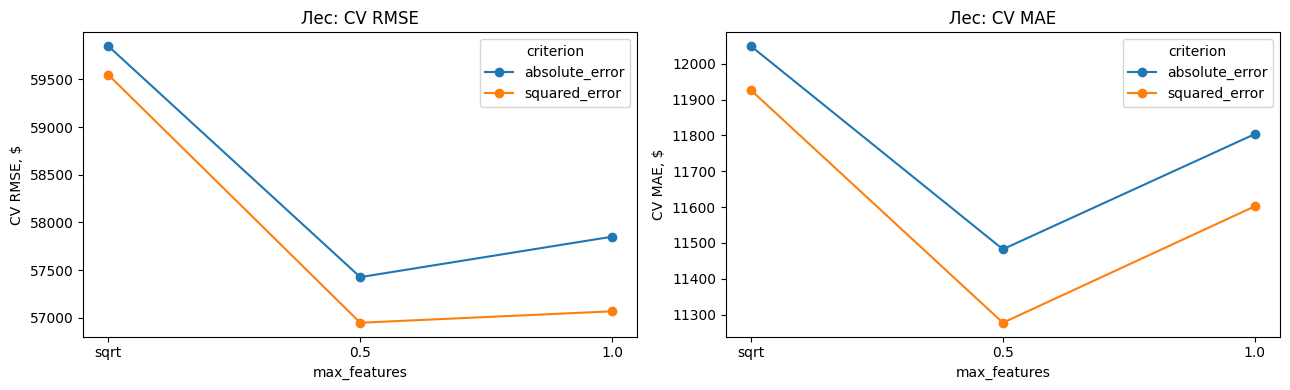

In [34]:
res_f = pd.DataFrame(gs_rf.cv_results_)
res_f['mf'] = res_f['param_regressor__model__max_features'].astype(str)
mf_order = ['sqrt', '0.5', '1.0']

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, name in [(axs[0], 'mean_test_rmse', 'CV RMSE, $'),
                      (axs[1], 'mean_test_mae', 'CV MAE, $')]:
    for crit, grp in res_f.groupby('param_regressor__model__criterion'):
        grp = grp.set_index('mf').loc[mf_order]
        ax.plot(mf_order, -grp[col], marker='o', label=crit)
    ax.set_xlabel('max_features'); ax.set_ylabel(name); ax.legend(title='criterion')
    ax.set_title(f'Лес: {name.split(",")[0]}')
fig.tight_layout()

display(res_f.assign(RMSE=-res_f['mean_test_rmse'], MAE=-res_f['mean_test_mae'])
        [['param_regressor__model__criterion', 'mf', 'RMSE', 'MAE']]
        .rename(columns={'param_regressor__model__criterion': 'criterion'}).round(0))

- **Ridge**

  Кривые train и CV плоские до alpha ≈ 1, дальше обе растут, а значит регуляризация ничего не даёт, оптимум лежит на плато. Отдельно видно, что CV-ошибка ниже train: выбросы при разбиении на фолды почти всегда попадают в обучающую часть

- **Бустинг**
  
  Шаг определяет число нужных итераций: при lr = 0.1 минимум достигается уже к сотой, при lr = 0.03 модель к этому моменту ещё далеко от него. Выберу lr=0.03 и 600 max iter

- **Лес**
  
  absolute_error проигрывает squared_error во всех точках, включая MAE. Причина в том, что лес учится на log(price): в логарифмической шкале дорогие машины отличаются от медианной втрое, а не в шестьдесят раз, поэтому квадратичный критерий здесь уже не уязвим к выбросам
  
  Беру max_features=0.5 как лучший по MAE

## H2. Линейная модель не хуже ансамблевых методов
## H3. Ridge (L2) обойдёт Lasso (L1) из-за мультиколлинеарности

Сравниваю на одних и тех же фолдах: константу, OLS, настроенные Ridge и Lasso - и два ансамбля с параметрами, выбранными в предыдущем разделе: лес с `max_features=0.5` и бустинг с шагом 0.03 на 600 итераций. Дерево оставляю как промежуточный ориентир: оно показывает, сколько даёт одна модель того семейства, из которого собран лес.

In [35]:
rf_best = RandomForestRegressor(n_estimators=200, max_features=0.5, random_state=SEED, n_jobs=-1)
gb_best = HistGradientBoostingRegressor(learning_rate=0.03, max_iter=600, random_state=SEED)

models = {
    'Константа':     make_model(DummyRegressor(strategy='median')),
    'OLS':           make_model(LinearRegression(), log_target=True),
    'Ridge*':        make_model(Ridge(alpha=alpha_r), log_target=True),
    'Lasso*':        make_model(Lasso(alpha=alpha_l, max_iter=50000), log_target=True),
    'Tree':          make_model(DecisionTreeRegressor(max_depth=8, min_samples_leaf=5,
                                                      random_state=SEED), log_target=True),
    'RandomForest*': make_model(rf_best, log_target=True),
    'HistGB*':       make_model(gb_best, log_target=True),
}
sc = {k: cv_scores(v) for k, v in models.items()}
display(pd.DataFrame([summary(k, v) for k, v in sc.items()]))

for key in ['test_rmse', 'test_mae']:
    paired('Ridge*', sc['Ridge*'], 'RandomForest*', sc['RandomForest*'], key)   # H2
    paired('Ridge*', sc['Ridge*'], 'HistGB*',       sc['HistGB*'],       key)   # H2
    paired('Ridge*', sc['Ridge*'], 'Lasso*',        sc['Lasso*'],        key)   # H3
    print()

,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,Константа,76153,37620,27578,3051,-0.048
1,OLS,55853,44536,13643,2603,0.522
2,Ridge*,55853,44536,13643,2603,0.522
3,Lasso*,55853,44536,13642,2603,0.522
4,Tree,57617,43753,14761,2548,0.475
5,RandomForest*,53382,45863,11333,3045,0.568
6,HistGB*,52078,46537,11014,3126,0.586


Ridge* - RandomForest* [RMSE]: +2470 (std 2176), p = 0.0078  ->  значимо
Ridge* - HistGB* [RMSE]: +3775 (std 3661), p = 0.0129  ->  значимо
Ridge* - Lasso* [RMSE]: -0 (std 0), p = 0.0579  ->  в пределах шума

Ridge* - RandomForest* [MAE]: +2310 (std 613), p = 0.0000  ->  значимо
Ridge* - HistGB* [MAE]: +2628 (std 818), p = 0.0000  ->  значимо
Ridge* - Lasso* [MAE]: +0 (std 0), p = 0.0067  ->  значимо



**H2 - не подтвердилась.**

Ridge проигрывает обоим ансамблям значимо по обеим метрикам: лесу 2470$ по RMSE (p = 0.008) и 2310$ по MAE (p < 0.0001), бустингу 3775$ и 2628$ (p = 0.013 и p < 0.0001). По R² разрыв 0.522 против 0.568 и 0.586.

При этом предпосылка гипотезы верна: линейные зависимости в данных есть, и видно это по тому, что Ridge уверенно обходит одиночное дерево (55.9k / 13.6k против 57.6k / 14.8k). Ошибка была не в наблюдении, а в переходе от него к выводу: «часть признаков влияет линейно» и «линейной модели достаточно» - разные утверждения.

Ансамбли берут сверх линейной модели взаимодействия: цена премиальной марки падает с пробегом иначе, чем массовой, электромобиль стареет не так, как бензиновый. Ridge складывает вклады признаков независимо и такое поймать не может, а деревья внутри ансамбля делят выборку на области и в каждой строят свою зависимость.

Цена вопроса - около 2.5k MAE при медианной цене 31k, то есть примерно 8%, и платится она интерпретируемостью: у Ridge есть коэффициент при каждом признаке, у ансамблей только важности. Бустинг с мелким шагом немного обходит лес (52.1k против 53.4k), но разница внутри погрешности.

In [36]:
# H3, вторая попытка: даём линейным моделям заведомо избыточное признаковое пространство
h3 = {'OLS + poly2':   cv_scores(make_model(LinearRegression(), log_target=True, poly=True)),
      'Ridge + poly2': cv_scores(make_model(Ridge(alpha=3.16), log_target=True, poly=True)),
      'Lasso + poly2': cv_scores(make_model(Lasso(alpha=2.15e-4, max_iter=50000), log_target=True, poly=True))}
display(pd.DataFrame([summary(k, v) for k, v in h3.items()]))

paired('Ridge+poly', h3['Ridge + poly2'], 'OLS+poly',   h3['OLS + poly2'])
paired('Ridge+poly', h3['Ridge + poly2'], 'Lasso+poly', h3['Lasso + poly2'])

# сколько коэффициентов Lasso занулил на базовых признаках
lasso_fit = make_model(Lasso(alpha=alpha_l, max_iter=50000), log_target=True).fit(X_train, y_train)
coef = lasso_fit.regressor_.named_steps['model'].coef_
print(f'\nLasso* на базовых признаках: ненулевых коэффициентов {(coef != 0).sum()} из {len(coef)}')

,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,OLS + poly2,54290,44390,12560,2583,0.548
1,Ridge + poly2,54298,44486,12511,2586,0.548
2,Lasso + poly2,54305,44641,12477,2586,0.548


Ridge+poly - OLS+poly [RMSE]: +9 (std 196), p = 0.8963  ->  в пределах шума
Ridge+poly - Lasso+poly [RMSE]: -7 (std 258), p = 0.9355  ->  в пределах шума

Lasso* на базовых признаках: ненулевых коэффициентов 50 из 53


**H3 - не подтвердилась.**

Ridge, Lasso и OLS дают одно и то же: 55853 у всех трёх, разница округляется до нуля. Парный тест выдаёт p = 0.0579 и p = 0.0067, но считает он различия в последних значащих цифрах - содержательного смысла в такой значимости нет. Полезное правило: если разница округляется до нуля, p-value смотреть уже незачем.

Причина в том, что предпосылка не выполняется. Мультиколлинеарность мешает OLS, когда признаков много относительно объектов; здесь объектов в 50 раз больше, а на графике из подбора видно, что кривые train и CV плоские до alpha ≈ 1 - модель не переобучается, подавлять нечего. Lasso при этом оставил 50 ненулевых коэффициентов из 53, то есть и отбирать нечего.

Расширение признакового пространства (poly2 - все попарные произведения числовых) гипотезу не спасло: OLS 54290, Ridge 54298, Lasso 54305, p = 0.90 и p = 0.94. Заодно видно, что сами попарные произведения дают линейной модели около 1.5k RMSE - часть тех взаимодействий, за счёт которых выигрывают ансамбли, но заметно меньшую

## H4. Признаки цвета не влияют на цену: их удаление не ухудшит RMSE

Проверяю удалением: обучаю одну и ту же модель со всеми признаками и без двух цветовых, сравниваю на одних фолдах. Делаю это и для Ridge, и для леса - линейная модель могла бы «не увидеть» цвет просто из-за своей формы

In [37]:
variants = {
    'оба цвета':      CAT,
    'без ext_color':  [c for c in CAT if c != 'ext_color_base'],
    'без int_color':  [c for c in CAT if c != 'int_color_base'],
    'без обоих':      [c for c in CAT if 'color' not in c],
}

for est, nm in [(Ridge(alpha=alpha_r), 'Ridge'),
                (RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1), 'RF')]:
    res = {k: cv_scores(make_model(est, log_target=True, cat=v)) for k, v in variants.items()}
    display(pd.DataFrame([summary(f'{nm}: {k}', v) for k, v in res.items()]))
    for k in ['без ext_color', 'без int_color', 'без обоих']:
        paired(f'{nm} оба цвета', res['оба цвета'], f'{nm} {k}', res[k], 'test_rmse')
    print()

,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,Ridge: оба цвета,55853,44536,13643,2603,0.522
1,Ridge: без ext_color,55903,44536,13635,2589,0.522
2,Ridge: без int_color,55971,44442,13657,2562,0.520
3,Ridge: без обоих,56036,44447,13661,2545,0.519


Ridge оба цвета - Ridge без ext_color [RMSE]: -50 (std 357), p = 0.6816  ->  в пределах шума
Ridge оба цвета - Ridge без int_color [RMSE]: -118 (std 405), p = 0.4029  ->  в пределах шума
Ridge оба цвета - Ridge без обоих [RMSE]: -184 (std 252), p = 0.0566  ->  в пределах шума



,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,RF: оба цвета,53331,45955,11581,3004,0.567
1,RF: без ext_color,53269,45956,11540,3006,0.568
2,RF: без int_color,53319,45951,11600,2999,0.567
3,RF: без обоих,53205,45997,11557,3004,0.569


RF оба цвета - RF без ext_color [RMSE]: +61 (std 146), p = 0.2397  ->  в пределах шума
RF оба цвета - RF без int_color [RMSE]: +11 (std 119), p = 0.7795  ->  в пределах шума
RF оба цвета - RF без обоих [RMSE]: +126 (std 131), p = 0.0182  ->  значимо



**H4 - подтвердилась.**

У Ridge ни один вариант удаления не ухудшает метрику значимо: без `ext_color_base` разница -50$ (p = 0.68), без `int_color_base` −118$ (p = 0.40), без обоих -184$ (p = 0.057). Знак минус означает, что версия без цвета даже чуть лучше.

У леса удаление обоих цветовых признаков метрику значимо улучшает: +126$, p = 0.018. То есть цвета не просто бесполезны, а слегка мешают - это лишние разреженные столбцы, по которым дерево иногда строит разбиения на шуме. С учётом того, что лес взят с `max_features=0.5`, эффект понятен: чем больше в наборе пустых признаков, тем чаще в половину, доступную разбиению, не попадают полезные.

Ниже в H5 это видно напрямую: оба цвета вместе дают +159$ к MAE у леса и +229$ у Ridge при перестановке - на фоне 7.8k у пробега это ноль

## H5. Самые важные признаки - hp и пробег

Считаю permutation importance по **исходным** колонкам (перестановка происходит до пайплайна), поэтому `brand` оценивается целиком, а не по отдельным OHE-столбцам - иначе сравнение с числовыми признаками было бы нечестным: у бренда 50 столбцов, у пробега один.

Метрика - прирост MAE при перемешивании признака. Считаю на тесте без трёх машин дороже 1 млн, чтобы важности не определялись тремя объектами

/usr/local/lib/python3.13/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,RandomForest,Ridge
accident,16.0,131.0
age,5017.0,5151.0
brand,5029.0,4449.0
clean_title,-21.0,146.0
cylinder,1320.0,969.0
engine_type,118.0,406.0
ext_color_base,25.0,41.0
fuel_type,212.0,292.0
hp,6623.0,2019.0
int_color_base,104.0,194.0


,RandomForest,Ridge
age,5028.0,5273.0
brand,5163.0,4530.0
milage,7867.0,5719.0
двигатель (hp+liter+cylinder),8881.0,5844.0
цвета (ext+int),159.0,229.0


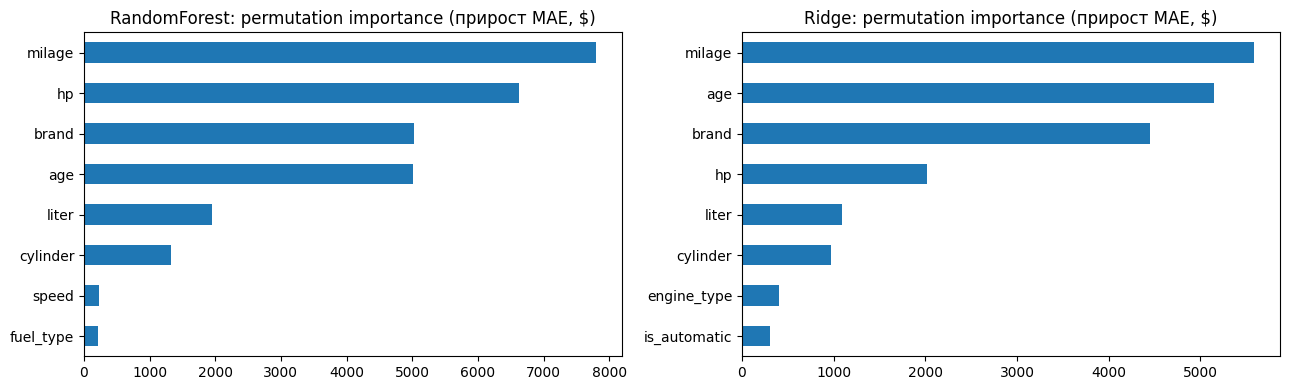

In [38]:
mask_te = y_test <= 1e6

rf = make_model(RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                      random_state=42, n_jobs=-1), log_target=True).fit(X_train, y_train)
ridge = make_model(Ridge(alpha=alpha_r), log_target=True).fit(X_train, y_train)

imp = {}
for nm, m in [('RandomForest', rf), ('Ridge', ridge)]:
    pi = permutation_importance(m, X_test[mask_te], y_test[mask_te], n_repeats=10,
                                random_state=42, scoring='neg_mean_absolute_error', n_jobs=-1)
    imp[nm] = pd.Series(pi.importances_mean, index=X.columns).sort_values(ascending=False)

display(pd.DataFrame(imp).round(0))

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nm, s) in zip(axs, imp.items()):
    s.head(8)[::-1].plot.barh(ax=ax)
    ax.set_title(f'{nm}: permutation importance (прирост MAE, $)')
fig.tight_layout()

# групповая перестановка: коррелированные признаки двигателя мешаем вместе
def group_permutation(model, Xv, yv, groups, n_repeats=10, seed=42):
    rng = np.random.default_rng(seed)
    base = mean_absolute_error(yv, model.predict(Xv))
    out = {}
    for name, cols in groups.items():
        scores = []
        for _ in range(n_repeats):
            Xp = Xv.copy()
            idx = rng.permutation(len(Xp))
            Xp[cols] = Xp[cols].values[idx]          # переставляем группу целиком, связи внутри сохраняются
            scores.append(mean_absolute_error(yv, model.predict(Xp)) - base)
        out[name] = np.mean(scores)
    return pd.Series(out).sort_values(ascending=False)

groups = {'двигатель (hp+liter+cylinder)': ['hp', 'liter', 'cylinder'],
          'milage': ['milage'], 'age': ['age'], 'brand': ['brand'],
          'цвета (ext+int)': ['ext_color_base', 'int_color_base']}

display(pd.DataFrame({'RandomForest': group_permutation(rf, X_test[mask_te], y_test[mask_te], groups),
                      'Ridge': group_permutation(ridge, X_test[mask_te], y_test[mask_te], groups)}).round(0))

**H5 - подтвердилась частично**

По одиночным перестановкам:

- RandomForest: `milage` (+7.8k к MAE), `hp` (+6.6k), `age` (+5.0k), `brand` (+5.0k), `liter` (+2.0k) - гипотеза выполняется буквально
- Ridge: `milage` (+5.6k), `age` (+5.2k), `brand` (+4.4k), `hp` (+2.0k) = `hp` только четвёртый.

Расхождение объяснимо: после логарифмирования цена почти линейно убывает с возрастом, и для линейной модели возраст ценнее мощности. Плюс `brand` после таргет-энкодинга стал одной содержательной колонкой со средней ценой марки и вошёл в топ-4 у обеих моделей.

Групповая перестановка меняет картину сильнее. Тройка `hp + liter + cylinder`, перемешанная целиком, даёт +8.9k у леса и +5.8k у Ridge - больше, чем любой отдельный признак у обеих моделей. По отдельности `hp` показывал 6.6k и 2.0k: при одиночной перестановке модель восстанавливает информацию по двум оставшимся признакам двигателя, и важность каждого занижается, у Ridge почти втрое. Корректная формулировка гипотезы была бы не «hp и пробег», а «характеристики двигателя и пробег».

Итоговая картина: цену определяют четыре блока - двигатель, пробег, возраст и марка. Цвета дают практически ноль.

## H6. Удаление выбросов с ценой > 1 млн сделает модели стабильнее

При этом разбиении гипотезу можно проверить буквально: две машины дороже миллиона попали в трейн, одна в тест. Проверяю три вещи:

1. что делает с тестовой метрикой единственный дорогой объект в тесте;
2. что будет, если убрать из трейна машины дороже 1 млн - ровно то, что сказано в гипотезе;
3. что будет при более агрессивной чистке - удалении верхнего 1% цен.

Оцениваю всё на **одном и том же** тесте: если убрать выбросы и из теста тоже, метрики улучшатся автоматически, и сравнение ничего не покажет.

In [39]:
q99 = y_train.quantile(0.99)
print('машин дороже $1 млн в трейне:', (y_train > 1e6).sum(), ', в тесте:', (y_test > 1e6).sum())
print(f'порог 99-го перцентиля: ${q99:,.0f}, это {(y_train > q99).sum()} машин')

subsets = {
    'трейн целиком':    (X_train, y_train),
    'без машин > $1M':  (X_train[y_train <= 1e6], y_train[y_train <= 1e6]),
    'без топ-1% цен':   (X_train[y_train <= q99], y_train[y_train <= q99]),
}

rows = []
for nm, (Xt, yt) in subsets.items():
    for mdl_nm, est in [('Ridge', Ridge(alpha=alpha_r)),
                        ('RandomForest', RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                                               random_state=SEED, n_jobs=-1))]:
        p = make_model(est, log_target=True).fit(Xt, yt).predict(X_test)
        rows.append({'модель': mdl_nm, 'обучение': nm, **report(y_test, p, 'весь тест')})
        rows.append({'модель': mdl_nm, 'обучение': nm, **report(y_test[mask_te], p[mask_te], 'тест без выбросов')})
display(pd.DataFrame(rows))

машин дороже $1 млн в трейне: 2 , в тесте: 1
порог 99-го перцентиля: $272,802, это 29 машин


,модель,обучение,выборка,RMSE,MAE,MedAE,MAPE %,R2
0,Ridge,трейн целиком,весь тест,51188,12706,5109,27.3,0.386
1,Ridge,трейн целиком,тест без выбросов,27252,11466,5108,27.2,0.670
2,RandomForest,трейн целиком,весь тест,48316,10208,4499,23.6,0.453
3,RandomForest,трейн целиком,тест без выбросов,20877,8959,4494,23.5,0.807
4,Ridge,без машин > $1M,весь тест,51234,12634,5142,27.0,0.384
5,Ridge,без машин > $1M,тест без выбросов,27264,11393,5138,27.0,0.670
6,RandomForest,без машин > $1M,весь тест,47706,10138,4584,23.3,0.466
7,RandomForest,без машин > $1M,тест без выбросов,20806,8908,4582,23.3,0.808
8,Ridge,без топ-1% цен,весь тест,52583,13070,5145,27.0,0.352
9,Ridge,без топ-1% цен,тест без выбросов,29601,11826,5144,26.9,0.611


In [40]:
p_ridge = make_model(Ridge(alpha=alpha_r), log_target=True).fit(X_train, y_train).predict(X_test)
out = df.loc[X_test.index[~mask_te], ['brand', 'model', 'age', 'milage', 'hp', 'price']].copy()
out['pred'] = p_ridge[~mask_te].round()
display(out)

n_out = (~mask_te).sum()
print(f'RMSE на всём тесте:                  {mean_squared_error(y_test, p_ridge) ** 0.5:,.0f}')
print(f'RMSE без {n_out} объектов из {len(y_test)}:        {mean_squared_error(y_test[mask_te], p_ridge[mask_te]) ** 0.5:,.0f}')

se = (y_test - p_ridge) ** 2
print(f'\nдоля этих {n_out} объектов в суммарном квадрате ошибки: {se[~mask_te].sum() / se.sum():.1%}')
print(f'MedAE: {median_absolute_error(y_test, p_ridge):,.0f} -> '
      f'{median_absolute_error(y_test[mask_te], p_ridge[mask_te]):,.0f}')
print(f'MAPE:  {np.mean(np.abs((y_test - p_ridge) / y_test)) * 100:.1f}% -> '
      f'{np.mean(np.abs((y_test[mask_te] - p_ridge[mask_te]) / y_test[mask_te])) * 100:.1f}%')

,brand,model,age,milage,hp,price,pred
3046,Porsche,Carrera GT Base,19,4400,605.0,1599000,95846.0


RMSE на всём тесте:                  51,188
RMSE без 1 объектов из 1203:        27,252

доля этих 1 объектов в суммарном квадрате ошибки: 71.7%
MedAE: 5,109 -> 5,108
MAPE:  27.3% -> 27.2%


**H6 - не подтвердилась.**

- Удаление двух машин дороже миллиона из обучения почти ничего не меняет: Ridge на тесте без выброса 27264 против 27252 (R² 0.670 в обоих случаях), лес 20806 против 20877. Разница меньше погрешности одного замера.
- Более агрессивная чистка (весь верхний 1% цен, 29 машин) ухудшает обе модели: Ridge 27252 → 29601 (R² 0.670 → 0.611), лес 20877 → 26304 (0.807 → 0.693). Модели теряют примеры дорогого сегмента и начинают систематически занижать цены.
- Единственная машина дороже миллиона в тесте - Porsche Carrera GT за 1.6M, модель предсказывает ей 96k. Один объект из 1203 даёт 71.7% суммарного квадрата ошибки и поднимает RMSE с 27.3k до 51.2k, роняя R² с 0.670 до 0.386. MedAE при этом меняется с 5109 до 5108, MAPE с 27.3% до 27.2%.

Удаление дорогих машин не делает модели стабильнее - оно делает стабильнее только метрику, и то потому, что из выборки убраны объекты с самым большим вкладом в квадратичную ошибку. Тот же эффект виден и в подборе гиперпараметров, где CV-ошибка оказалась ниже train: выбросы почти всегда попадают в обучающую часть фолда.

Вывод: ориентироваться стоит на MedAE и MAPE, а дорогие объекты - проверять на достоверность. Maserati за 2.95M в трейне это ошибка ввода, а Porsche Carrera GT - настоящая машина, которую модель просто не может предсказать, не видев ничего похожего

## Отбор признаков (SelectKBest)

,модель,RMSE,RMSE_std,MAE,MAE_std,R2
0,k = 5,59344,43235,14878,2542,0.448
1,k = 10,57371,44089,14392,2573,0.492
2,k = 20,56330,44451,13910,2673,0.513
3,k = 30,56009,44530,13712,2667,0.520
4,k = 40,55928,44614,13602,2664,0.522
5,k = 50,55753,44593,13612,2620,0.524
6,k = all,55853,44536,13643,2603,0.522


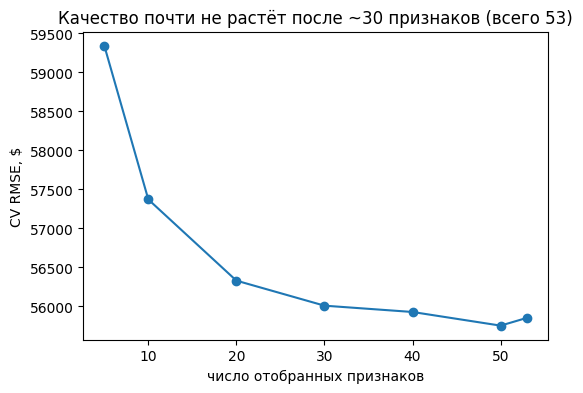

In [41]:
n_feat = make_prep().fit_transform(X_train, np.log(y_train)).shape[1]
ks = [5, 10, 20, 30, 40, 50, 'all']

rows = []
for k in ks:
    pipe = Pipeline([('prep', make_prep()),
                     ('sel', SelectKBest(f_regression, k=k)),
                     ('model', Ridge(alpha=alpha_r))])
    est = TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)
    rows.append(summary(f'k = {k}', cv_scores(est)))
sel = pd.DataFrame(rows)
display(sel)

plt.figure(figsize=(6, 4))
plt.plot([k if k != 'all' else n_feat for k in ks], sel['RMSE'], marker='o')
plt.xlabel('число отобранных признаков'); plt.ylabel('CV RMSE, $')
plt.title(f'Качество почти не растёт после ~30 признаков (всего {n_feat})');

**Вывод.** Качество растёт с числом признаков, но выходит на плато рано: 5 признаков дают RMSE 59.3k, 20 - 56.3k, 30 - 56.0k, дальше изменения в пределах сотни долларов. Формально лучший результат у k = 50 (55753), на 100$ лучше полного набора - это заведомо шум.

То есть после ~30 признаков добавлять нечего. Отбор здесь не улучшает модель, а позволяет её упростить: при n >> p Ridge сам гасит влияние малополезных столбцов, что согласуется с выводом H3 - переобучения, с которым надо бороться, в этой конфигурации нет.

Заодно видно, во что обошёлся таргет-энкодинг: признаков всего 53 против 92 с OHE, при том что качество не упало

# Финальная модель и разбор ошибок

Сравниваю на тесте лучшую линейную модель и оба ансамбля

In [42]:
final = make_model(Ridge(alpha=alpha_r), log_target=True).fit(X_train, y_train)
final_rf = make_model(rf_best, log_target=True).fit(X_train, y_train)
final_gb = make_model(gb_best, log_target=True).fit(X_train, y_train)

rows = []
for nm, m in [('Ridge*', final), ('RandomForest*', final_rf), ('HistGB*', final_gb)]:
    p = m.predict(X_test)
    rows.append({'модель': nm, **report(y_test, p, 'весь тест')})
    rows.append({'модель': nm, **report(y_test[mask_te], p[mask_te], 'без выбросов > $1M')})
display(pd.DataFrame(rows))

,модель,выборка,RMSE,MAE,MedAE,MAPE %,R2
0,Ridge*,весь тест,51188,12706,5109,27.3,0.386
1,Ridge*,без выбросов > $1M,27252,11466,5108,27.2,0.670
2,RandomForest*,весь тест,47735,10073,4322,23.0,0.466
3,RandomForest*,без выбросов > $1M,20983,8844,4318,22.9,0.805
4,HistGB*,весь тест,47588,10365,4448,22.7,0.469
5,HistGB*,без выбросов > $1M,22432,9163,4440,22.6,0.777


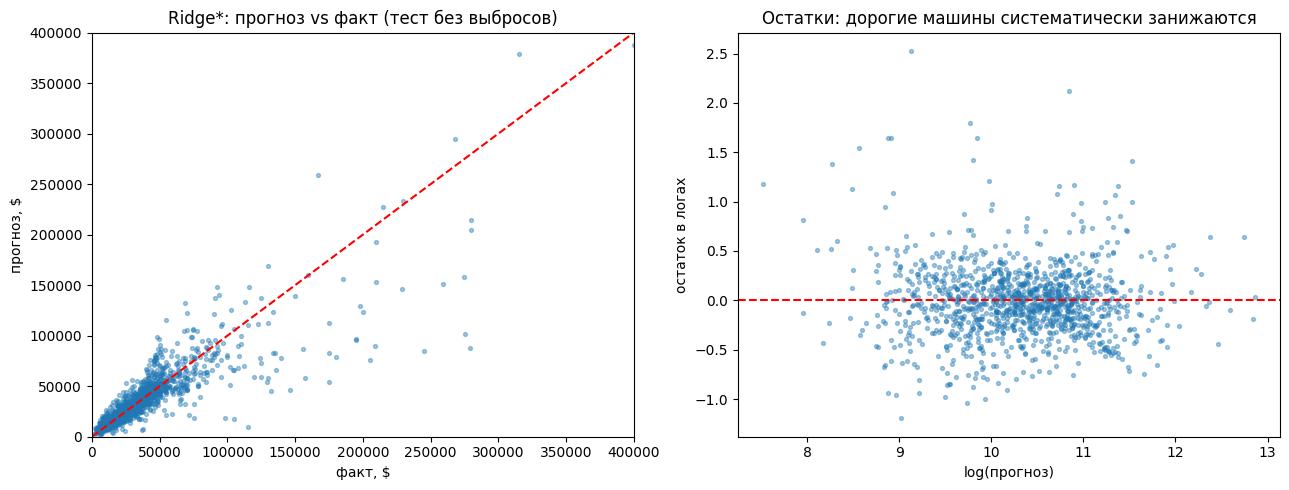

In [43]:
p = final.predict(X_test)
fig, axs = plt.subplots(1, 2, figsize=(13, 5))

axs[0].scatter(y_test[mask_te], p[mask_te], s=8, alpha=0.4)
lims = [0, 4e5]
axs[0].plot(lims, lims, 'r--')
axs[0].set_xlim(lims); axs[0].set_ylim(lims)
axs[0].set_xlabel('факт, $'); axs[0].set_ylabel('прогноз, $')
axs[0].set_title('Ridge*: прогноз vs факт (тест без выбросов)')

resid = np.log(y_test[mask_te]) - np.log(p[mask_te])
axs[1].scatter(np.log(p[mask_te]), resid, s=8, alpha=0.4)
axs[1].axhline(0, color='r', ls='--')
axs[1].set_xlabel('log(прогноз)'); axs[1].set_ylabel('остаток в логах')
axs[1].set_title('Остатки: дорогие машины систематически занижаются')
fig.tight_layout()

Остатки в логах симметричны вокруг нуля в массовом сегменте (10k–100k), но справа видно систематическое занижение: чем дороже машина, тем сильнее модель недооценивает цену. Это ожидаемо - дорогие объекты редкие, а `model` с информацией о комплектации не используется.

Итоги на тесте без Porsche: Ridge даёт MedAE 5108 при медианной цене 31k, то есть ошибку около 16% от цены, MAPE 27.2%, R² 0.670. Оба ансамбля заметно лучше: лес - MedAE 4318, MAPE 22.9%, R² 0.805; бустинг - 4440, 22.6%, 0.777. На всём тесте, вместе с Porsche, бустинг чуть впереди леса по RMSE (47588 против 47735) - он меньше промахивается на единственной дорогой машине.

Финальный выбор: любой из ансамблей, если нужна точность, и Ridge, если нужна объяснимость

# Итоги по гипотезам

**№1**

Гипотеза: log(price) улучшит RMSE

Итог: подтвердилась для линейной модели, частично для ансамбля

Почему: Ridge: RMSE 61.3k → 55.9k, MAE 22.5k → 13.6k (p = 0.0008). У леса значимо только по MAE (13.5k → 11.6k, p = 0.009), по RMSE p = 0.080: логарифм не меняет разбиения, только усреднение в листьях

**№2**

Гипотеза: линейная модель не хуже ансамблей

Итог: не подтвердилась

Почему: Ridge проигрывает лесу 2.3k MAE и бустингу 2.6k MAE (оба p < 0.0001). Предпосылка при этом верна: линейные зависимости есть, и Ridge обходит одиночное дерево. Ансамбли выигрывают за счёт взаимодействий, которые линейная модель не ловит

**№3**

Гипотеза: Ridge обойдёт Lasso

Итог: не подтвердилась

Почему: Ridge = Lasso = OLS до доллара. Предпосылка не выполняется: 2806 объектов на 53 признака, кривые train и CV плоские, Lasso оставил 50 коэффициентов из 53. Расширение до poly2 тоже ничего не дало (p = 0.90)

**№4**

Гипотеза: цвета не влияют, удаление не ухудшит RMSE

Итог: подтвердилась

Почему: У Ridge ни один вариант удаления не значим. У леса удаление обоих цветов метрику значимо улучшает (+126$, p = 0.018)

**№5**

Гипотеза: самые важные признаки - hp и пробег

Итог: подтвердилась частично

Почему: Для леса - да. Для Ridge hp только четвёртый, впереди пробег, возраст и марка. При групповой перестановке блок hp+liter+cylinder выходит на первое место у обеих моделей - корректнее было бы «двигатель и пробег»

**№6**

Гипотеза: удаление машин дороже 1 млн стабилизирует модели

Итог: не подтвердилась

Почему: Удаление двух таких машин из трейна не меняет качество, удаление верхнего 1% ухудшает обе модели. Один дорогой объект в тесте даёт 71.7% квадрата ошибки при изменении MedAE на 1$ - проблема в метрике, а не в моделях


# Общий вывод
По CV-R²: константа -0.05, «возраст + пробег» 0.15, полный набор признаков 0.52 (с логарифмом таргета), лес 0.568, бустинг 0.586. На тесте без выброса картина заметно лучше (Ridge 0.670, лес 0.805) - разрыв показывает, насколько сильно две дорогие машины в обучающей выборке портят кросс-валидационные оценки.

Основной прирост дали не модели, а работа с данными: признаки, вытащенные из текстового описания двигателя, KNN-заполнение пропусков в них, логарифм цены и таргет-энкодинг марки. Переход от линейной модели к ансамблю добавил ещё около 8% MAE